# Phase 1: Exploratory Data Analysis & Preprocessing Infrastructure
## AI4I 2020 Predictive Maintenance Dataset

**Task:** Binary Machine Failure Prediction
**Target:** `Machine failure` (0 = Normal, 1 = Failure)
**Planned Sequence Model:** PyTorch LSTM with 30-timestep sliding windows

> **IMPORTANT:** This notebook serves strictly for exploratory data analysis, failure mode leakage investigation, and preprocessing validation. Model training is strictly deferred to Phase 2.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load raw dataset
data_path = Path('../../data/raw/ai4i2020.csv')
if not data_path.exists():
    data_path = Path('data/raw/ai4i2020.csv')

df = pd.read_csv(data_path)
print(f'Dataset shape: {df.shape}')
print(f'Missing values: {df.isnull().sum().sum()}')
print(f'Duplicate rows: {df.duplicated().sum()}')
print(f'Columns: {list(df.columns)}')


Dataset shape: (10000, 14)
Missing values: 0
Duplicate rows: 0
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 1. Target Class Distribution Analysis

Investigating class imbalance for `Machine failure`. Severe imbalance is standard in industrial asset monitoring and requires careful validation and loss weighting (e.g. `pos_weight` in `BCEWithLogitsLoss`).

Machine Failure Counts:
0 (Normal):   9,661 (96.61%)
1 (Failure):    339 (3.39%)
Imbalance ratio: 28.50 : 1


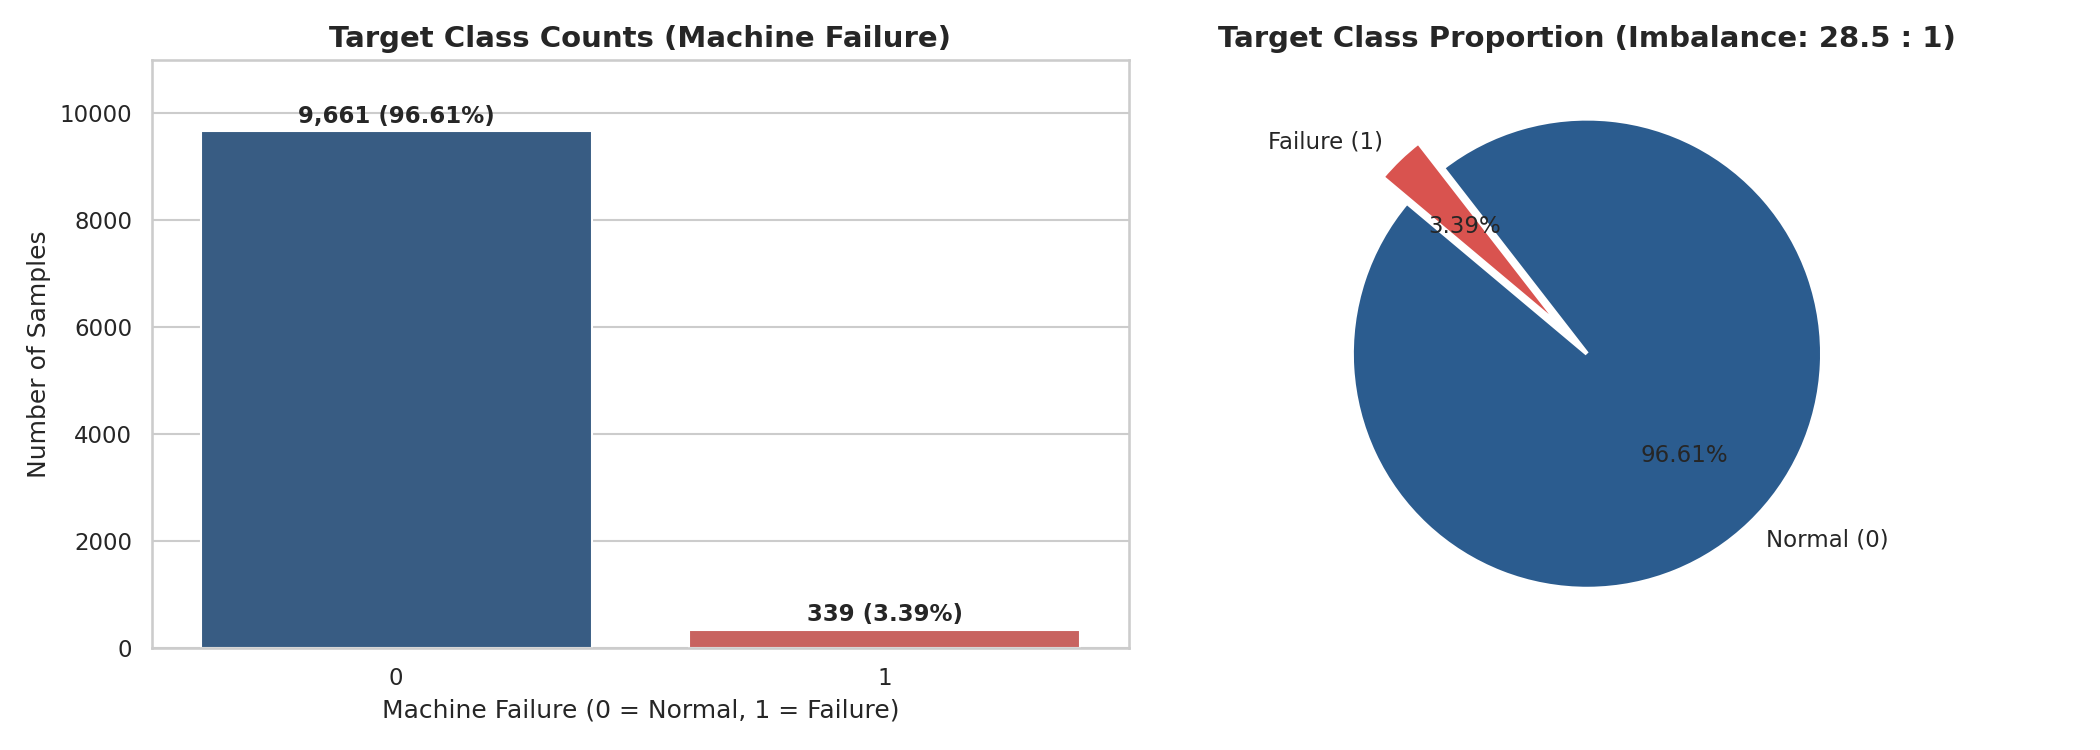

In [2]:
target = 'Machine failure'
counts = df[target].value_counts()
print('Machine Failure Counts:')
print(f'0 (Normal):   {counts[0]:,} ({counts[0]/len(df)*100:.2f}%)')
print(f'1 (Failure):    {counts[1]:,} ({counts[1]/len(df)*100:.2f}%)')
print(f'Imbalance ratio: {counts[0]/counts[1]:.2f} : 1')

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=['#2b5c8f', '#d9534f'], legend=False, ax=axes[0])
axes[0].set_title('Target Class Counts (Machine Failure)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Machine Failure (0 = Normal, 1 = Failure)')
axes[0].set_ylabel('Number of Samples')
axes[1].pie(counts.values, labels=['Normal (0)', 'Failure (1)'], autopct='%1.2f%%',
            colors=['#2b5c8f', '#d9534f'], startangle=140, explode=(0, 0.15),
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Target Class Proportion (Imbalance: 28.5 : 1)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Sensor Feature Distributions

Analysis of the 5 input features:
1. `Air temperature [K]`
2. `Process temperature [K]`
3. `Rotational speed [rpm]`
4. `Torque [Nm]`
5. `Tool wear [min]`

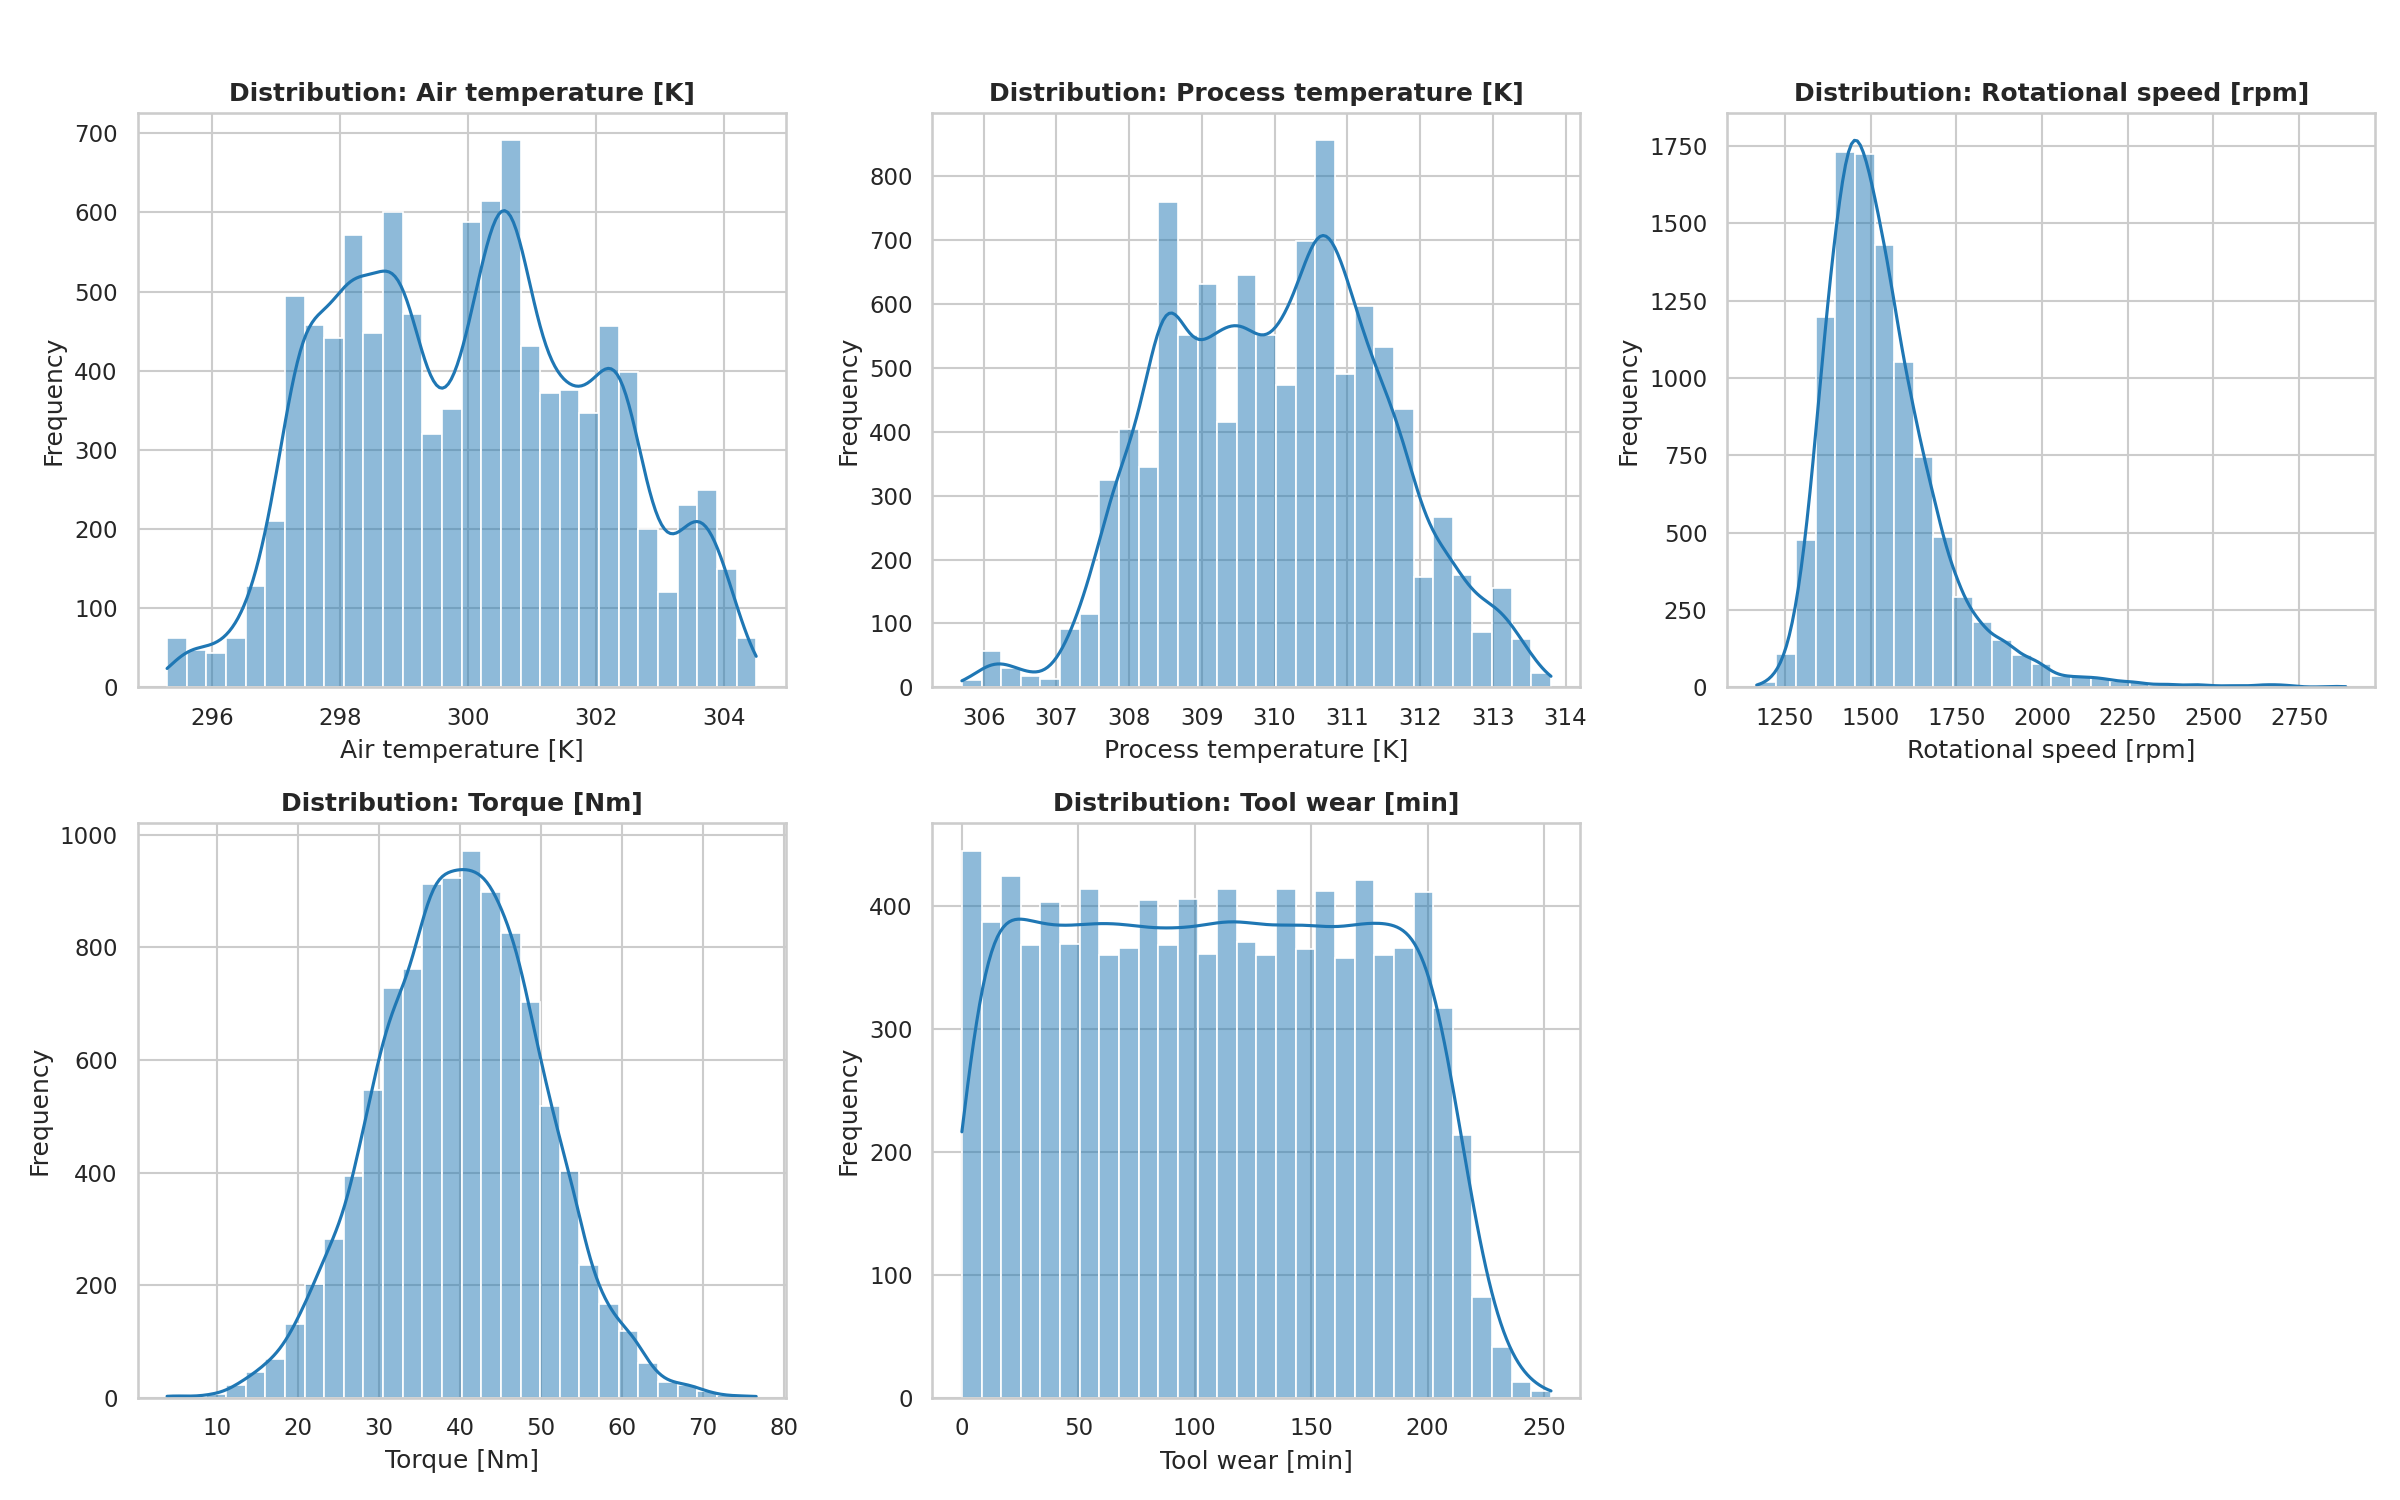

In [3]:
features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#1f77b4', bins=30)
    axes[i].set_title(f'Distribution: {col}', fontsize=12, fontweight='bold')
axes[5].axis('off')
plt.suptitle('Sensor Feature Distributions (AI4I 2020 Dataset)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Sensor Boxplots Grouped by Machine Failure

Comparing sensor variance between healthy operation and failure states.

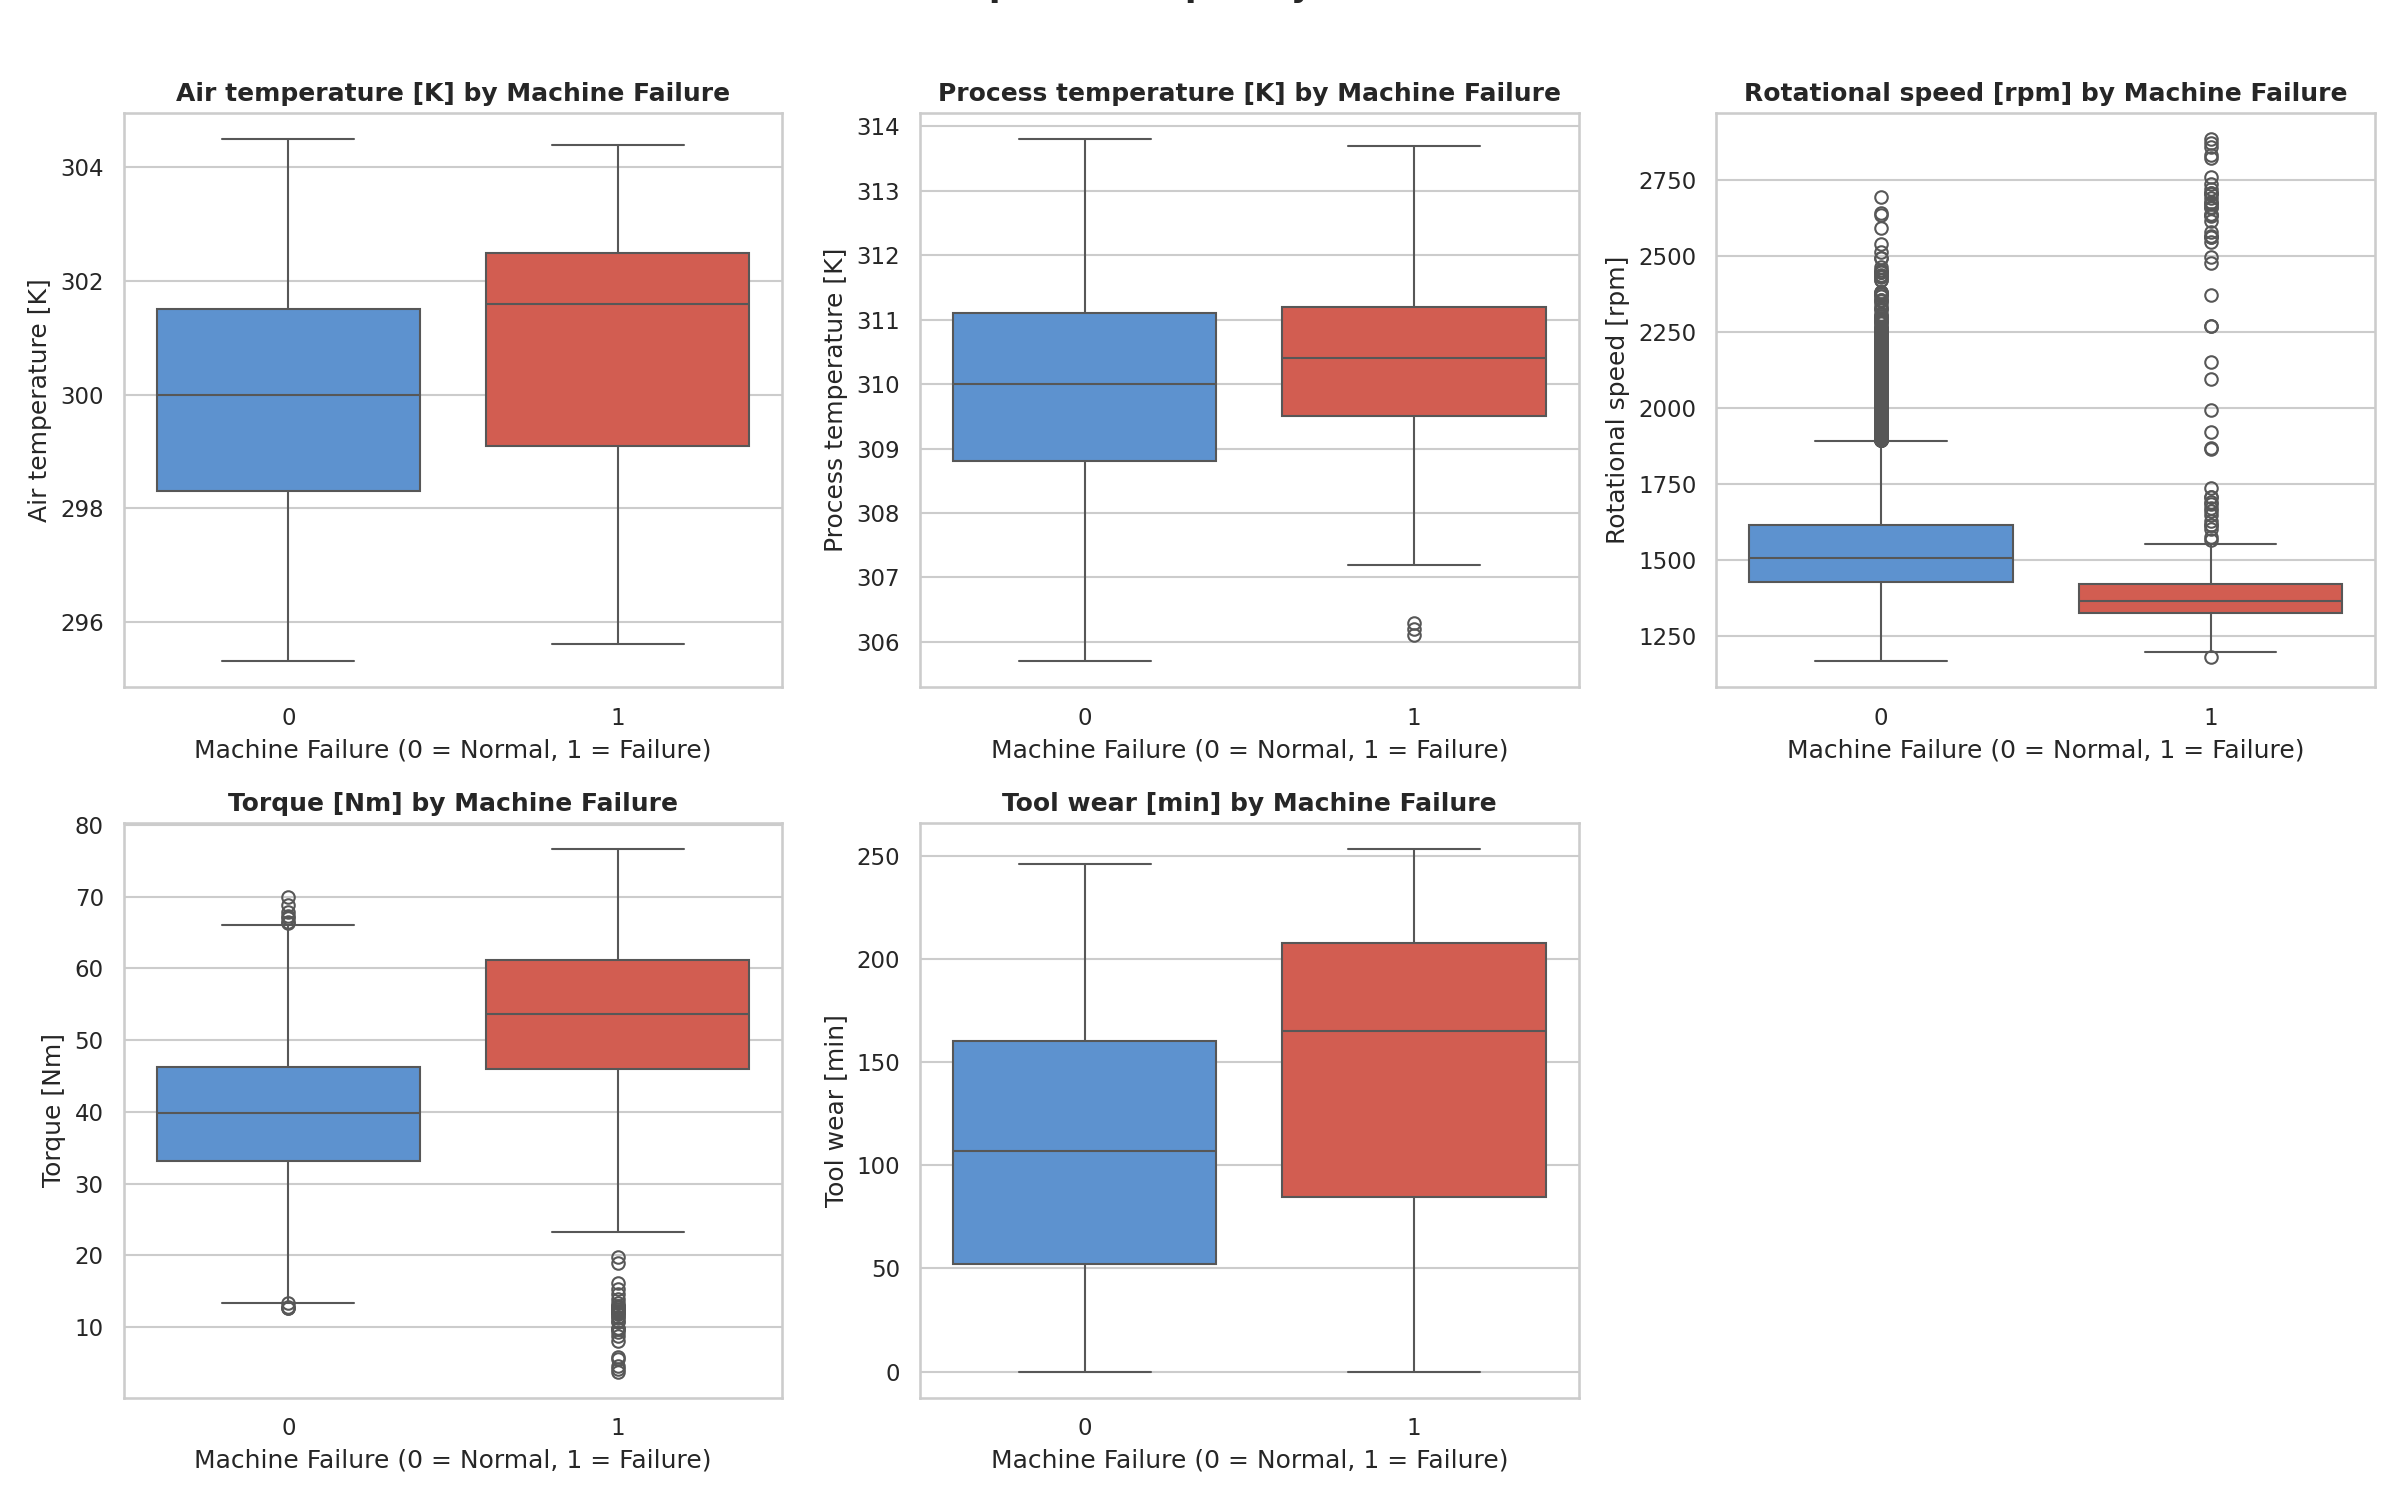

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(x=target, y=col, hue=target, data=df, ax=axes[i], palette=['#4a90e2', '#e74c3c'], legend=False)
    axes[i].set_title(f'{col} by Machine Failure', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Machine Failure (0 = Normal, 1 = Failure)')
axes[5].axis('off')
plt.suptitle('Sensor Boxplots Grouped by Machine Failure', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 4. Descriptive Statistics Grouped by Machine Failure

Numerical breakdown of sensor characteristics during normal (0) vs failure (1) operation.

In [5]:
print('=== SENSOR STATISTICS GROUPED BY MACHINE FAILURE ===')
for f in features:
    normal_stats = df[df[target] == 0][f]
    failure_stats = df[df[target] == 1][f]
    unit = f.split('[')[-1].split(']')[0] if '[' in f else ''
    print(f'Feature: {f}')
    print(f'  Normal (0) : Mean={normal_stats.mean():.2f} {unit}, Std={normal_stats.std():.2f} {unit}, Median={normal_stats.median():.2f} {unit}, Range=[{normal_stats.min():.2f}, {normal_stats.max():.2f}]')
    print(f'  Failure (1): Mean={failure_stats.mean():.2f} {unit}, Std={failure_stats.std():.2f} {unit}, Median={failure_stats.median():.2f} {unit}, Range=[{failure_stats.min():.2f}, {failure_stats.max():.2f}]')
    print()

=== SENSOR STATISTICS GROUPED BY MACHINE FAILURE ===
Feature: Air temperature [K]
  Normal (0) : Mean=299.97 K, Std=1.99 K, Median=300.00 K, Range=[295.30, 304.50]
  Failure (1): Mean=300.89 K, Std=2.07 K, Median=300.80 K, Range=[295.60, 304.40]

Feature: Process temperature [K]
  Normal (0) : Mean=310.00 K, Std=1.49 K, Median=310.00 K, Range=[305.70, 313.80]
  Failure (1): Mean=310.29 K, Std=1.36 K, Median=310.20 K, Range=[306.40, 313.50]

Feature: Rotational speed [rpm]
  Normal (0) : Mean=1540.26 rpm, Std=167.39 rpm, Median=1506.00 rpm, Range=[1183.00, 2886.00]
  Failure (1): Mean=1496.49 rpm, Std=384.94 rpm, Median=1362.00 rpm, Range=[1168.00, 2861.00]

Feature: Torque [Nm]
  Normal (0) : Mean=39.63 Nm, Std=9.47 Nm, Median=39.80 Nm, Range=[3.80, 76.60]
  Failure (1): Mean=50.17 Nm, Std=16.37 Nm, Median=53.40 Nm, Range=[13.40, 76.60]

Feature: Tool wear [min]
  Normal (0) : Mean=106.69 min, Std=62.95 min, Median=106.00 min, Range=[0.00, 253.00]
  Failure (1): Mean=143.78 min, Std=72

## 5. Correlation Matrix & Target Leakage Investigation

### Target Leakage Rationale:
Columns `TWF` (Tool Wear Failure), `HDF` (Heat Dissipation Failure), `PWF` (Power Failure), `OSF` (Overstrain Failure), and `RNF` (Random Failure) represent the specific breakdown modes that constitute the ground-truth target `Machine failure`.
- Including them in model inputs would cause **catastrophic target leakage**: the model would simply memorize the ground-truth failure flags rather than learning the physical degradation indicators from sensor telemetry.
- Consequently, all five failure mode flags must be strictly **excluded** from the input feature space.

Cross-tabulation: Machine failure vs Failure Modes active:
Any Mode Active     0    1
Machine failure           
0                9643   18
1                   9  330

Correlation with Machine failure:
Machine failure            1.000000
HDF                        0.575800
OSF                        0.531083
PWF                        0.522812
TWF                        0.362904
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
RNF                        0.004516
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64


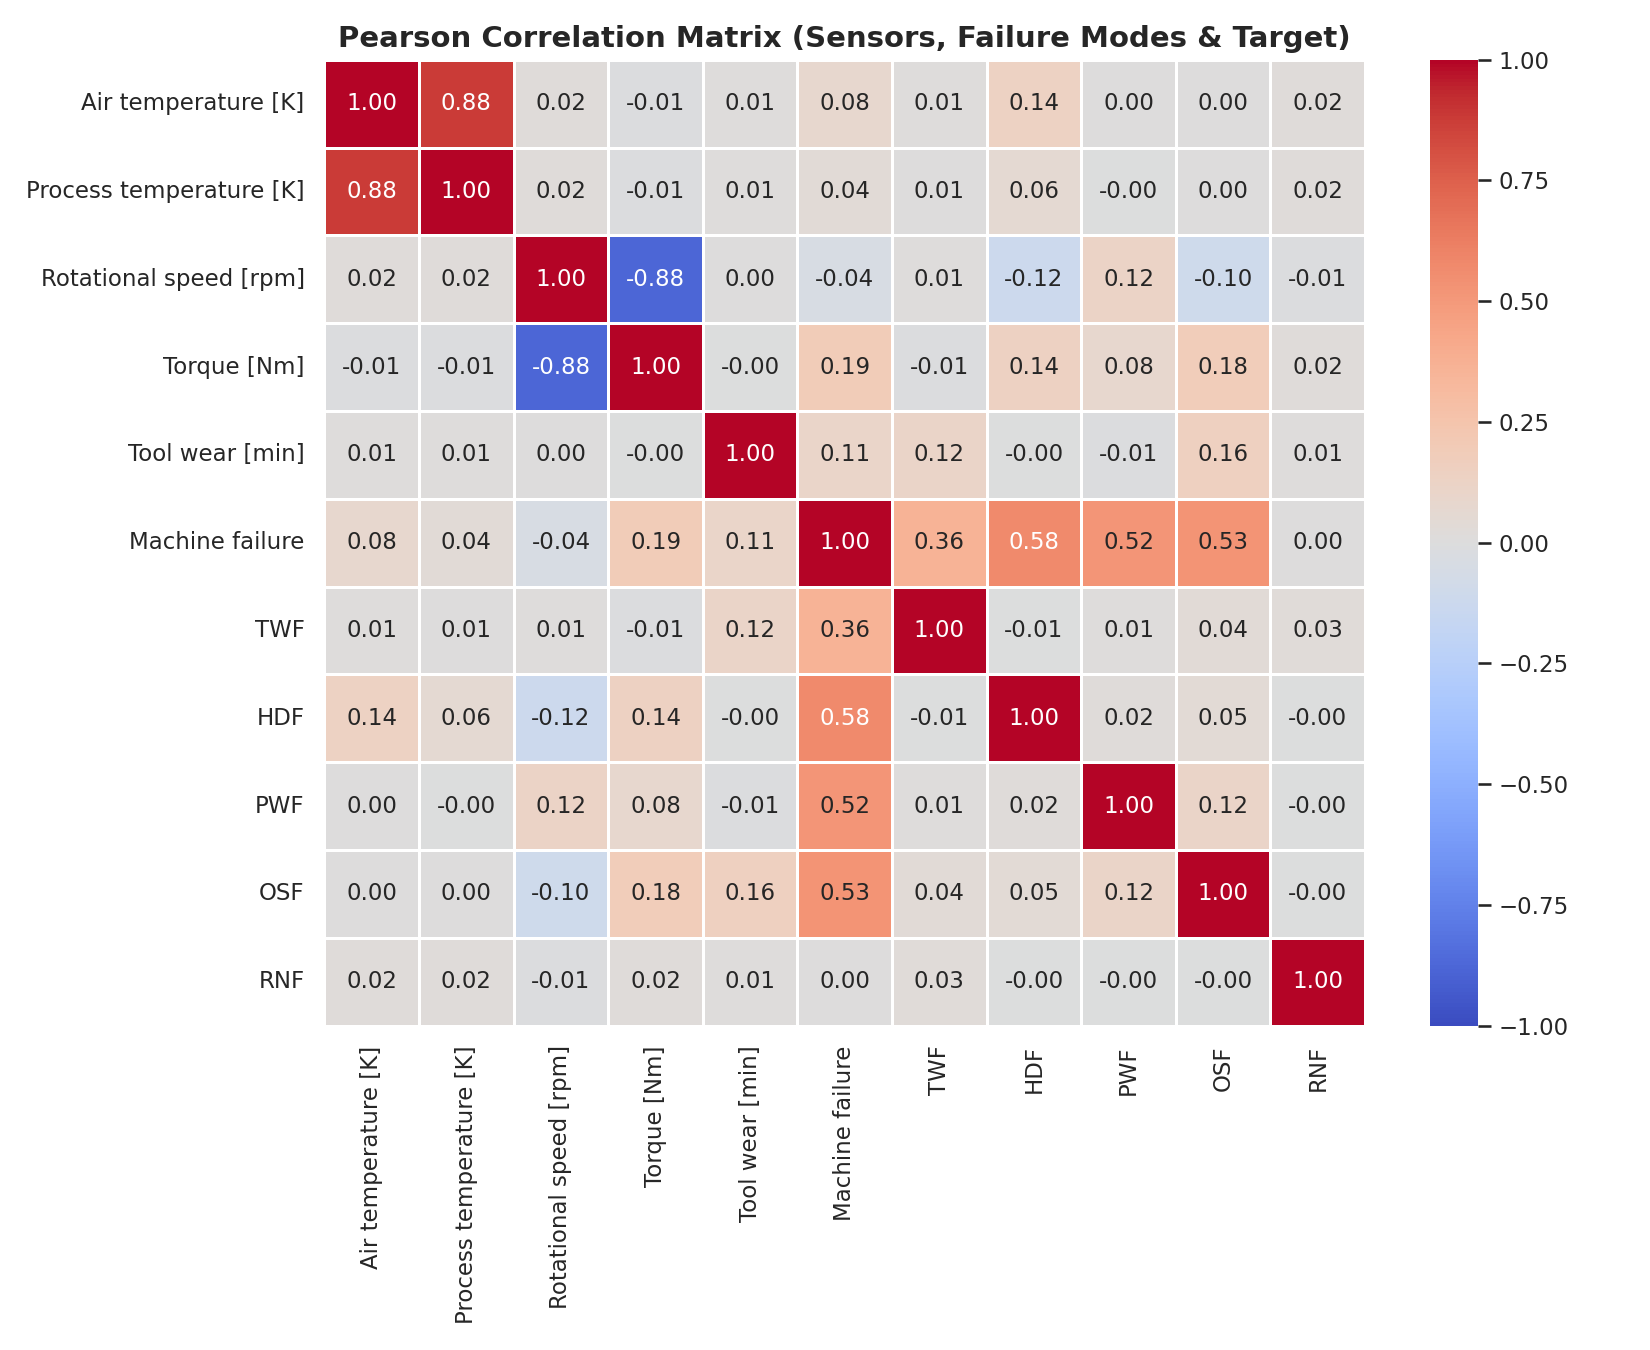

In [6]:
corr_cols = features + [target, 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
any_mode = (df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum(axis=1) > 0).astype(int)
print('Cross-tabulation: Machine failure vs Failure Modes active:')
print(pd.crosstab(df[target], any_mode, rownames=['Machine failure'], colnames=['Any Mode Active']))
print('\nCorrelation with Machine failure:')
print(df[corr_cols].corr()[target].sort_values(ascending=False))

# Heatmap
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title('Pearson Correlation Matrix (Sensors, Failure Modes & Target)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Sequential Temporal Continuity for LSTM Modeling

`Tool wear [min]` increases continuously across consecutive rows until reaching maintenance reset thresholds. This demonstrates that the dataset possesses sequential chronological dependency. **Random shuffling is prohibited** as it would destroy temporal autocorrelation and create sequence leakage.

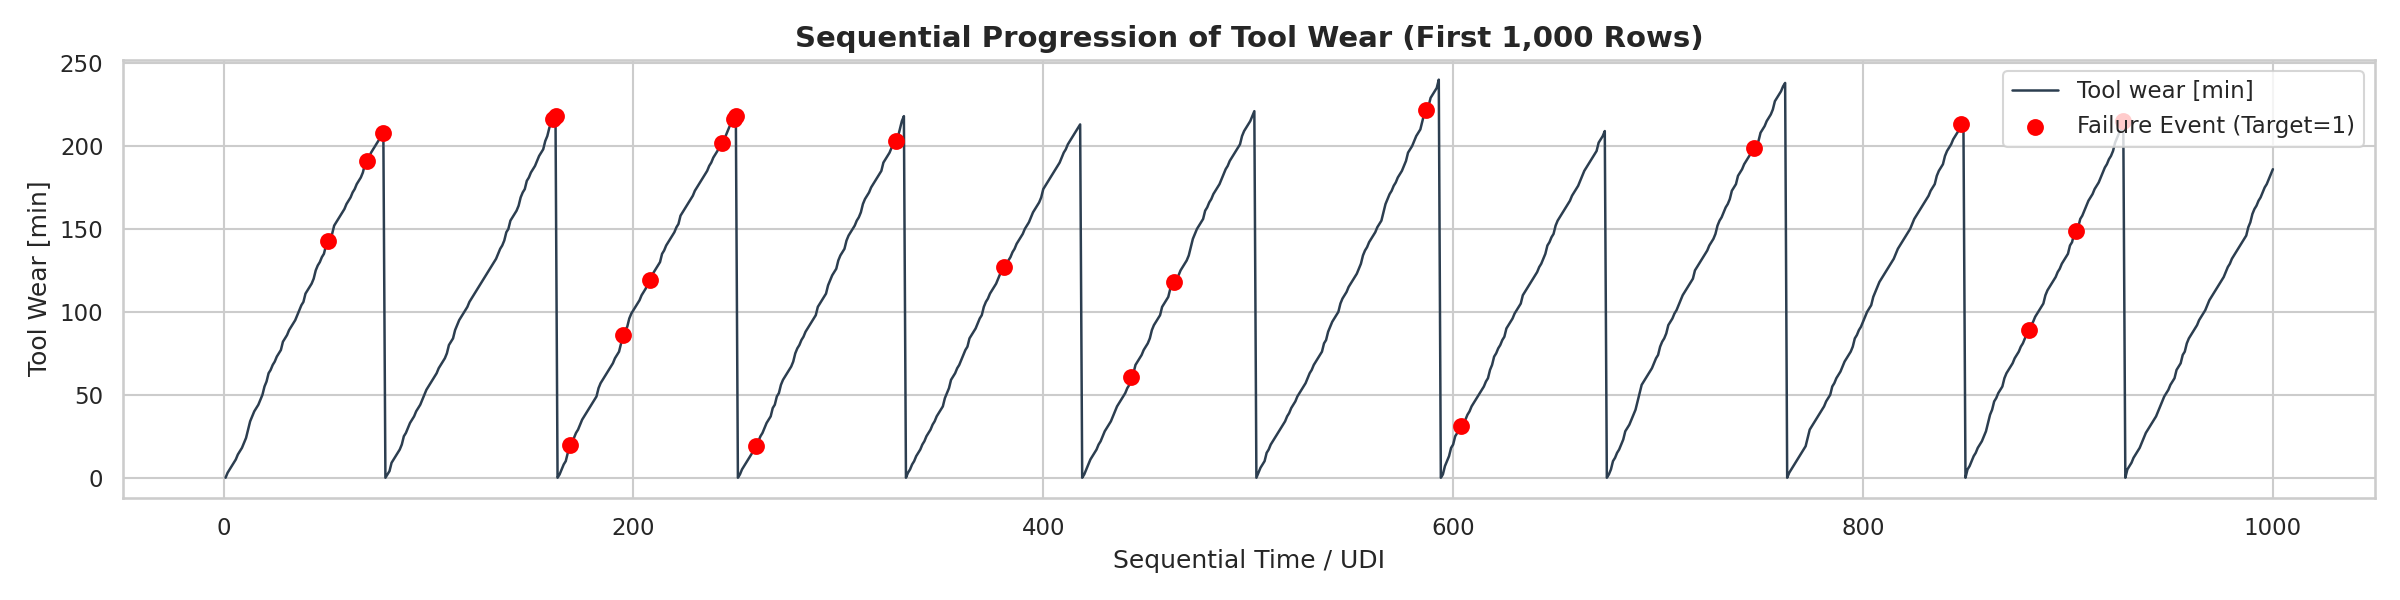

In [7]:
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(df['UDI'][:1000], df['Tool wear [min]'][:1000], color='#2c3e50', label='Tool wear [min]', lw=1.2)
fail_sample = df.iloc[:1000]
fails = fail_sample[fail_sample[target] == 1]
ax.scatter(fails['UDI'], fails['Tool wear [min]'], color='red', s=50, zorder=5, label='Failure Event (Target=1)')
ax.set_title('Sequential Progression of Tool Wear (First 1,000 Rows)', fontsize=14, fontweight='bold')
ax.set_xlabel('Sequential Time / UDI')
ax.set_ylabel('Tool Wear [min]')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## Summary & Conclusions for Phase 2 Modeling

1. **Features Selected:** The 5 continuous sensor measurements: `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, and `Tool wear [min]`.
2. **Target Variable:** `Machine failure` (binary 0/1).
3. **Excluded Columns:** `UDI`, `Product ID`, `Type`, and the 5 diagnostic failure modes (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) to prevent target leakage.
4. **Class Imbalance:** 339 positive cases (3.39%) vs 9,661 negative cases (96.61%). A pos_weight of ~28.5 or focal loss should be used during training.
5. **Data Scaling Rule:** Standard scaling must be fit strictly on training data (`X_train`) only, preserving validation and test set integrity.
6. **Sliding Windows:** 30 timesteps with step stride 1 are generated using `ml/preprocessing/sequence_utils.py`.